# 🏦 Deal Review Pipeline — V2
### Parallel Expert Panel · RAG Regulatory Knowledge · Human-in-the-Loop · Checkpointing

**Before running**, start Ollama:
```bash
ollama serve
ollama pull gemma4:e4b
ollama pull nomic-embed-text
```

## Architecture — V2 vs V1

| | V1 | **V2** |
|---|---|---|
| Execution | Sequential (Extract → Compliance → Risk) | **Parallel fan-out** (3 agents run simultaneously) |
| JSON extraction | Regex / string parsing | **`with_structured_output()` + Pydantic** |
| Compliance | Hard-coded dict | **Pure rule-based Python (if/else on extracted terms)** |
| Escalation | Print message | **`interrupt()` — real Human-in-the-Loop** |
| Audit trail | None | **`MemorySaver` checkpointing** |
| Tool schemas | Plain docstrings | **Pydantic `args_schema`** |
| Confidence | None | **Per-agent confidence + re-route logic** |

```
                     DEAL REVIEW PIPELINE — V2
  ──────────────────────────────────────────────────────────────────

  📄 PDF
    │
    ▼
  ┌─────────────────────────────────────────┐
  │  🔍  EXTRACTOR  (with_structured_output) │
  │  Pydantic DealTerms — no regex parsing   │
  └──────────────────┬──────────────────────┘
                     │  Send (parallel fan-out)
        ┌────────────┼────────────┐
        │            │            │
        ▼            ▼            ▼
  ┌──────────┐ ┌──────────┐ ┌──────────┐
  │ ⚖️ COMP. │ │ 📊 FIN.  │ │ 🎲 RISK  │
  │Specialist│ │ Analyst  │ │Quantifier│
  │          │ │          │ │          │
  │ Pure     │ │structured│ │calc tools│
  │ if/else  │ │ output   │ │+conf.    │
  │ on terms │ │          │ │          │
  └────┬─────┘ └────┬─────┘ └────┬─────┘
       │            │            │
       └────────────┼────────────┘
                    │  fan-in (operator.add reducer)
                    ▼
  ┌─────────────────────────────────────────┐
  │  🔮  SYNTHESIZER  (with_structured_output│
  │  Aggregates panel · sets confidence     │
  └──────────────────┬──────────────────────┘
                     │
          ┌──────────┴──────────┐
          │ requires_escalation?│
         YES                   NO
          │                    │
          ▼                    │
  ┌──────────────┐             │
  │ 👤  HUMAN    │             │
  │   REVIEW     │             │
  │ interrupt()  │             │
  └──────┬───────┘             │
         │                     │
         └──────────┬──────────┘
                    ▼
  ┌─────────────────────────────────────────┐
  │  📋  REPORT GENERATOR + CHECKPOINTER    │
  │  Full audit trail saved to MemorySaver  │
  └─────────────────────────────────────────┘
  ──────────────────────────────────────────────────────────────────
```

## How It Works — Quick Summary

A PDF goes in, a structured credit decision comes out. Six nodes run in order, with three running simultaneously in the middle.

**1 — Extractor** reads the PDF and pulls out all loan facts into a typed object (borrower, amount, LTV, DTI, credit score, etc.) using a single LLM call. No regex. No guessing.

**2 — Three Specialists run in parallel** the moment extraction finishes:

- **Compliance** — no LLM at all. Pure Python `if/else` checks each number against hard policy limits. Deterministic, instant, always 100% confident.
- **Financial Analyst** — one LLM call. Reads the numbers and gives a qualitative opinion: *"LTV is adequate, DTI is strong."* Interprets, doesn't calculate.
- **Risk Quantifier** — LLM + two math tools. The model calls `calc_credit_risk` and `calc_concentration_risk`, which run fixed formulas. The LLM assembles the composite score from the tool outputs.

**3 — Synthesizer** waits for all three to finish, then makes a single credit committee decision (APPROVE / REJECT / ESCALATE / CONDITIONAL) using one LLM call that sees all three reports.

**4 — Human Review** (only if escalated) — the pipeline pauses completely and waits for a human to approve or reject. Resumes exactly where it left off.

**5 — Report** assembles everything into one final audit document. No LLM needed.

> Total LLM calls: **6** (1 extractor + 0 compliance + 1 financial + ~3 risk loop + 1 synthesizer). Total tool calls: **2** (both in the risk node). The three parallel nodes run concurrently, so wall-clock time is the slowest of the three — not the sum.

LangChain / LangGraph Functions — Complete Reference

  Function: llm.with_structured_output(Schema)
  Where used: Extractor, Financial Analyst, Synthesizer
  What it does: Forces the LLM to return a filled Pydantic object instead of free text. No parsing
    needed.
  ────────────────────────────────────────
  Function: .invoke([messages])
  Where used: Every LLM call
  What it does: Runs the model once with a list of messages and returns the response.
  ────────────────────────────────────────
  Function: SystemMessage(content=...)
  Where used: Every agent
  What it does: The "standing instructions" given to the LLM before the conversation — sets its role

    and rules.
  ────────────────────────────────────────
  Function: HumanMessage(content=...)
  Where used: Every agent
  What it does: The actual question or data being sent to the LLM for this specific call.
  ────────────────────────────────────────
  Function: @tool(args_schema=Schema)
  Where used: Risk tools
  What it does: Turns a regular Python function into a callable tool the LLM can invoke. The schema
    tells the LLM what inputs to provide.
  ────────────────────────────────────────
  Function: create_react_agent(llm, tools, response_format=Schema)
  Where used: Risk Quantifier
  What it does: Builds a ReAct loop: Think → Call tool → Read result → Think again → Final
  structured
    answer. The response_format ensures the exit answer matches the schema.
  ────────────────────────────────────────
  Function: agent.invoke({"messages": [...]})                                                       
  Where used: Risk Quantifier
  What it does: Runs the full ReAct loop and returns the final state including structured_response. 
  ────────────────────────────────────────                                                          
  Function: result["structured_response"]                                                           
  Where used: Risk Quantifier
  What it does: Accesses the final Pydantic object produced by response_format — no second LLM call.
  ────────────────────────────────────────                                                          
  Function: StateGraph(DealState)                                                                   
  Where used: Graph builder
  What it does: Creates a blank pipeline flowchart that tracks state of type DealState through every
                                                                                                    
    node.
  ────────────────────────────────────────
  Function: builder.add_node(name, fn)                                                              
  Where used: Graph builder
  What it does: Registers a Python function as a named box in the flowchart.                        
  ────────────────────────────────────────                                                          
  Function: builder.add_edge(a, b)                                                                  
  Where used: Graph builder
  What it does: Draws an unconditional arrow: after a always go to b.                               
  ────────────────────────────────────────                                                          
  Function: builder.add_conditional_edges(src, fn, targets)                                         
  Where used: Graph builder
  What it does: Calls fn(state) after src to decide where to go. Used for fan-out and escalation    
    routing.                                                                                        
  ────────────────────────────────────────
  Function: builder.compile(checkpointer=...)                                                       
  Where used: Graph builder
  What it does: Locks the graph and attaches the checkpointer. Returns the runnable graph object.   
  ────────────────────────────────────────                                                          
  Function: Send(node_name, state)                                                                  
  Where used: Fan-out router
  What it does: Launches a specific node immediately with a copy of the state. Returning a list of  
    Sends starts them all in parallel.                                                              
  ────────────────────────────────────────
  Function: Annotated[list, operator.add]                                                           
  Where used: DealState
  What it does: Tells LangGraph to merge parallel results by appending, not overwriting. The three  
    specialists all write to the same field and all three results survive.                          
  ────────────────────────────────────────
  Function: interrupt(packet)                                                                       
  Where used: Human review node
  What it does: Completely pauses the pipeline and surfaces packet to the caller. Resumes only when 
    Command(resume=...) is passed back.                                                             
  ────────────────────────────────────────
  Function: Command(resume={...})                                                                   
  Where used: Resume cell
  What it does: Tells a paused graph to continue from the interrupt() point, passing the human's    
    input as the return value.                                                                      
  ────────────────────────────────────────
  Function: MemorySaver()                                                                           
  Where used: Checkpointer
  What it does: Saves a snapshot of the full state after every node. Enables pause/resume, replay,  
    and audit.                                                                                      
  ────────────────────────────────────────
  Function: graph.get_state_history(config)                                                         
  Where used: Checkpoints cell
  What it does: Returns every saved snapshot for a given thread_id, in reverse chronological order. 
  ────────────────────────────────────────                                                          
  Function: graph.invoke(initial, config)                                                           
  Where used: Run cell
  What it does: Executes the full graph from START to END (or until an interrupt). 

## Step 1 — Install

In [1]:
# This line downloads and installs all the external libraries this project needs.
# Think of it like installing apps on your phone before you can use them.
#
# langchain        — the main toolkit for building AI pipelines
# langchain-ollama — connects LangChain to the Ollama model running on your machine
# langchain-community — extra community-built tools for LangChain
# langgraph        — lets us draw a flowchart of AI agents and run it as code
# pypdf            — reads and extracts text from PDF files
# pydantic         — validates data (makes sure numbers are numbers, strings are strings, etc.)

%pip install -q langchain langchain-ollama langchain-community langgraph pypdf pydantic

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlx-use 0.0.3 requires langchain==0.3.14, but you have langchain 1.2.17 which is incompatible.
mlx-use 0.0.3 requires langchain-anthropic==0.3.3, but you have langchain-anthropic 1.4.3 which is incompatible.
mlx-use 0.0.3 requires langchain-google-genai==2.0.8, but you have langchain-google-genai 4.2.2 which is incompatible.
mlx-use 0.0.3 requires langchain-ollama==0.2.2, but you have langchain-ollama 1.1.0 which is incompatible.
mlx-use 0.0.3 requires langchain-openai==0.3.1, but you have langchain-openai 1.2.1 which is incompatible.
streamlit 1.37.1 requires rich<14,>=10.14.0, but you have rich 15.0.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 2 — Imports

In [ ]:
# "import" means: bring this library into our script so we can use its features.
# Each line below loads a specific tool we need.

import operator   # gives us operator.add — used to merge results from parallel agents
import json       # converts Python objects to/from JSON text format
import uuid       # generates unique random IDs (e.g. "DEAL-4A3F91")
import datetime   # gets the current date and time for report timestamps

# "Annotated" lets us attach extra info to a type (e.g. "this list uses operator.add to merge")
# "TypedDict" lets us define a dictionary where each key has a specific type
# "Literal" restricts a value to a fixed set of options (e.g. only "PASS", "FAIL", or "CONDITIONAL")
from typing import Annotated, TypedDict, Literal

# ChatOllama — the AI language model running locally via Ollama
from langchain_ollama import ChatOllama

# tool          — decorator that turns a plain Python function into something the AI can call
# HumanMessage  — represents the "user" side of a conversation with the AI
# SystemMessage — represents the "instructions" given to the AI before the conversation starts
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage

# StateGraph — the main class that lets us build a flowchart of AI agents
# START, END  — special markers for the beginning and end of the flowchart
from langgraph.graph import StateGraph, START, END

# Send      — used to launch multiple agents at the same time (parallel execution)
# interrupt — pauses the pipeline and waits for a human to provide input
# Command   — used to resume a paused pipeline with human input
from langgraph.types import Send, interrupt, Command

# MemorySaver     — saves a snapshot of the pipeline state after every step (for audit trail)
# create_react_agent — builds an AI agent that can think, call tools, and think again (ReAct loop)
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import create_react_agent

# BaseModel — the base class for defining structured data schemas with Pydantic
# Field     — lets us add descriptions and validation rules to each field in a schema
from pydantic import BaseModel, Field

# PdfReader — opens a PDF file and extracts its text content page by page
from pypdf import PdfReader

print('imports OK')

## Step 3 — Pydantic Schemas

All data flowing through the pipeline is **typed and validated**. No more regex JSON parsing.

In [3]:
# ── What are these "schemas"? ────────────────────────────────────────
# A schema is like a form with labelled fields.
# Instead of letting the AI return free-form text that we have to guess the structure of,
# we define exactly what fields we want and what type each one should be.
# Pydantic then guarantees the AI fills every field correctly — no missing data, no wrong types.

# ── DealTerms — the loan facts extracted from the PDF ───────────────
# This is the "extraction form". The AI reads the PDF and fills this in.
# The description= text in each Field is what the AI reads to understand what to extract.
class DealTerms(BaseModel):
    borrower:      str   = Field(description="Borrower / obligor name")
    amount_usd:    float = Field(description="Total loan amount in USD")
    ltv:           float = Field(description="Loan-to-value ratio as decimal (e.g. 0.75)")  # 75% → 0.75
    dti:           float = Field(description="Debt-to-income ratio as decimal")
    credit_score:  int   = Field(description="FICO / credit score 300-850")
    rate_pct:      float = Field(description="Annual interest rate percentage")
    term_months:   int   = Field(description="Loan term in months")
    jurisdiction:  str   = Field(description="Borrower jurisdiction or state")
    property_type: str   = Field(description="Asset or property type")
    purpose:       str   = Field(description="Stated loan purpose")

# ── ComplianceFindings — what the compliance agent reports back ──────
# Literal["PASS", "FAIL", "CONDITIONAL"] means status can ONLY be one of those three words.
# ge=0.0, le=1.0 means confidence must be between 0 and 1 (0% to 100%).
# default_factory=list means "start with an empty list if nothing is provided".
class ComplianceFindings(BaseModel):
    status:           Literal["PASS", "FAIL", "CONDITIONAL"]
    failed_rules:     list[str] = Field(default_factory=list)   # list of rules that were broken
    regulatory_notes: list[str] = Field(default_factory=list)   # extra notes from the agent
    confidence:       float     = Field(ge=0.0, le=1.0)         # how sure the agent is (0=not sure, 1=certain)
    reasoning:        str                                        # plain-text explanation of the verdict

# ── FinancialFindings — what the financial analyst reports back ──────
class FinancialFindings(BaseModel):
    ltv_assessment:  str                                          # e.g. "LTV is within acceptable range"
    dti_assessment:  str
    rate_assessment: str
    financial_health: Literal["STRONG", "ADEQUATE", "WEAK", "CRITICAL"]
    strengths:       list[str] = Field(default_factory=list)
    concerns:        list[str] = Field(default_factory=list)
    confidence:      float     = Field(ge=0.0, le=1.0)
    reasoning:       str

# ── RiskFindings — what the risk quantifier reports back ────────────
class RiskFindings(BaseModel):
    credit_risk_score:        float = Field(ge=0, le=100)   # 0 = safest, 100 = riskiest
    concentration_risk_score: float = Field(ge=0, le=100)   # how big this deal is vs the whole portfolio
    composite_risk_score:     float = Field(ge=0, le=100)   # weighted average of the two above
    risk_level:               Literal["LOW", "MEDIUM", "HIGH", "CRITICAL"]
    mitigants:                list[str] = Field(default_factory=list)  # things that reduce the risk
    confidence:               float     = Field(ge=0.0, le=1.0)
    reasoning:                str

# ── PanelDecision — the final combined verdict from all three agents ─
class PanelDecision(BaseModel):
    decision:            Literal["APPROVE", "CONDITIONAL_APPROVE", "REJECT", "ESCALATE"]
    overall_risk_score:  float     = Field(ge=0, le=100)
    requires_escalation: bool                                   # True = needs a human to review
    conditions:          list[str] = Field(default_factory=list)  # conditions attached to approval
    key_risks:           list[str] = Field(default_factory=list)
    executive_summary:   str                                    # short plain-English summary
    panel_confidence:    float     = Field(ge=0.0, le=1.0)     # average confidence across all agents

print('schemas OK')

schemas OK


## Step 4 — Configuration + LLM + Rules

In [ ]:
# ── Which AI model to use ────────────────────────────────────────────
# MODEL is the language model that reads, thinks, and writes (like a brain).
# temperature=0 means "always give the most predictable/consistent answer" (no randomness).
# num_ctx=8192 means the model can read up to 8192 tokens (~6000 words) at once.
MODEL = "gemma4:e4b"
llm   = ChatOllama(model=MODEL, temperature=0, num_ctx=8192)

# ── Hard policy thresholds ───────────────────────────────────────────
# These are the numerical limits used by compliance and risk nodes.
# For example: a loan with LTV above 0.80 (80%) automatically fails compliance.
# These values come from internal policy — no LLM involved, pure hard rules.
RULES = {
    "max_loan_usd":          50_000_000,      # maximum loan size: $50 million
    "max_ltv":               0.80,            # loan cannot exceed 80% of property value
    "min_credit_score":      620,             # borrower must have at least this credit score
    "max_dti":               0.43,            # monthly debt payments cannot exceed 43% of income
    "max_rate_pct":          18.0,            # interest rate cannot exceed 18%
    "escalation_usd":        10_000_000,      # deals over $10M require human review
    "blocked_jurisdictions": ["OFAC", "FATF-blacklist"],  # banned locations — no deals allowed
}

print(f"LLM  : {MODEL}")
print(f"Rules: {len(RULES)} thresholds loaded")

## Step 5 — Tools with Pydantic Input Schemas

Risk tools declare an `args_schema` — the LLM sees the field descriptions and validates before calling.
Compliance needs no tools — it runs pure Python if/else against the RULES dict.

In [ ]:
# ── What are "tools"? ────────────────────────────────────────────────
# Tools are regular Python functions that the AI is allowed to call.
# The @tool decorator registers the function so the AI knows it exists.
# The AI reads the function's docstring to decide when and how to use it.
# The args_schema (a Pydantic class) tells the AI exactly what inputs the function expects.

# ── RISK TOOLS ───────────────────────────────────────────────────────
# The compliance specialist no longer needs any tools — it uses pure Python rule checks.
# Only the risk quantifier uses tools (math formulas, not LLM reasoning).

class CreditRiskInput(BaseModel):
    credit_score: int   = Field(description="FICO credit score 300-850")
    ltv:          float = Field(description="Loan-to-value ratio 0-1")
    dti:          float = Field(description="Debt-to-income ratio 0-1")
    rate_pct:     float = Field(description="Annual interest rate percentage")

@tool(args_schema=CreditRiskInput)
def calc_credit_risk(credit_score: int, ltv: float, dti: float, rate_pct: float) -> str:
    """Calculate composite credit risk score 0–100 (higher = riskier). Use with borrower metrics."""
    # Each metric contributes a "penalty" to the score.
    # If the metric is within the safe zone, the penalty is 0.
    # The worse the metric, the larger the penalty — up to a max of 100.
    score_pen = max(0.0, (750 - credit_score) / 130) * 40  # low credit score = higher penalty (max 40pts)
    ltv_pen   = max(0.0, (ltv   - 0.60) / 0.20)      * 25  # high LTV = higher penalty (max 25pts)
    dti_pen   = max(0.0, (dti   - 0.35) / 0.08)      * 20  # high DTI = higher penalty (max 20pts)
    rate_pen  = max(0.0, (rate_pct - 6.0) / 12.0)    * 15  # high rate = higher penalty (max 15pts)
    score     = round(min(100.0, score_pen + ltv_pen + dti_pen + rate_pen), 1)  # cap at 100
    return json.dumps({"credit_risk_score": score,
                       "breakdown": {"credit": round(score_pen,1), "ltv": round(ltv_pen,1),
                                     "dti": round(dti_pen,1), "rate": round(rate_pen,1)}})


class ConcentrationRiskInput(BaseModel):
    amount_usd:          float = Field(description="Loan amount in USD")
    portfolio_limit_usd: float = Field(default=500_000_000, description="Portfolio limit in USD")

@tool(args_schema=ConcentrationRiskInput)
def calc_concentration_risk(amount_usd: float, portfolio_limit_usd: float = 500_000_000) -> str:
    """Calculate concentration risk as percentage of total portfolio."""
    # If this one deal is a large % of our total portfolio, that's risky — all eggs in one basket.
    pct   = (amount_usd / portfolio_limit_usd) * 100      # what % of our $500M portfolio is this?
    score = round(min(100.0, pct * 5), 1)                 # scale to 0-100 (20% of portfolio = score 100)
    tier  = "HIGH" if score > 60 else "MEDIUM" if score > 30 else "LOW"
    return json.dumps({"concentration_pct": round(pct, 2),
                       "concentration_risk_score": score, "tier": tier})


# Risk quantifier uses both math tools
RISK_TOOLS = [calc_credit_risk, calc_concentration_risk]

print("tools OK")

## Step 6 — State

`specialist_results` uses **`operator.add`** as a reducer — each parallel agent appends its result, and they're merged automatically when the fan-in fires.

In [6]:
# ── What is "State"? ─────────────────────────────────────────────────
# State is the shared memory that every node in the pipeline can read and write to.
# Think of it like a baton in a relay race — each runner (node) picks it up,
# does their job, updates it, and passes it to the next.
#
# TypedDict means it's a regular Python dictionary, but with strict field names and types.
# Every node receives the full state and returns only the fields it changed.

# SpecialistResult is one agent's report — we collect three of these (compliance, financial, risk)
class SpecialistResult(TypedDict):
    specialist: str    # which agent produced this: "compliance", "financial", or "risk"
    findings:   dict   # the full findings object (ComplianceFindings / FinancialFindings / RiskFindings)
    confidence: float  # how confident this agent is in its findings (0.0 to 1.0)

class DealState(TypedDict):
    # ── Inputs (set at the start, never change) ──────────────────────
    deal_id:   str   # unique identifier for this deal run, e.g. "DEAL-4A3F91"
    deal_text: str   # raw text extracted from the PDF

    # ── Stage 1: after the extractor runs ────────────────────────────
    terms: DealTerms | None  # structured loan facts (None until the extractor fills it in)

    # ── Stage 2: after all three parallel specialists run ────────────
    # Annotated[list, operator.add] is special:
    # normally if two agents both write to the same field, one would overwrite the other.
    # operator.add tells LangGraph to APPEND instead — so all three results are collected.
    specialist_results: Annotated[list[SpecialistResult], operator.add]

    # ── Stage 3: after the synthesizer runs ──────────────────────────
    panel_decision:      PanelDecision | None  # the combined verdict from all three agents
    requires_escalation: bool                  # True if a human needs to review this deal

    # ── Stage 4: after human review (only if escalated) ──────────────
    human_decision: str | None   # the human's override decision (e.g. "APPROVE")
    human_notes:    str | None   # any notes the human added

    # ── Stage 5: final output ─────────────────────────────────────────
    final_report: dict | None    # the complete report assembled at the end

print("state OK")

state OK


## Step 7 — Nodes

### 7a — Extractor (structured output)

In [7]:
# ── Node 1: Extractor ────────────────────────────────────────────────
# This is the first step in the pipeline.
# It reads the raw PDF text and extracts structured loan terms from it.
#
# A "node" in LangGraph is just a regular Python function that:
#   - Takes the current state as input
#   - Does some work
#   - Returns a dictionary of only the fields it changed

def node_extract(state: DealState) -> dict:
    print("\n📄 [Extractor] Parsing deal document...")

    # with_structured_output(DealTerms) tells the LLM:
    # "Don't write a free-text response. Fill in this exact form instead."
    # Pydantic validates every field — if the LLM makes a mistake, it's caught here.
    structured = llm.with_structured_output(DealTerms)

    # We send two messages to the LLM:
    #   SystemMessage = the standing instructions ("you are an analyst, use decimals...")
    #   HumanMessage  = the actual PDF text to analyse
    # [:6000] limits the text to the first 6000 characters to avoid exceeding the model's memory
    terms = structured.invoke([
        SystemMessage(content=(
            "You are a financial document analyst. Extract all loan terms precisely. "
            "Ratios must be decimals (0.75 not 75%). If a field is missing, make a "
            "reasonable inference from context."
        )),
        HumanMessage(content=f"Extract terms from:\n\n{state['deal_text'][:6000]}"),
    ])

    # Print a summary so we can see what was extracted
    print(f"   ✓ Borrower : {terms.borrower}")
    print(f"   ✓ Amount   : ${terms.amount_usd:,.0f}")
    print(f"   ✓ LTV      : {terms.ltv:.1%}  DTI: {terms.dti:.1%}  Credit: {terms.credit_score}")

    # Return only the fields this node changed.
    # LangGraph merges these updates into the full state automatically.
    # We also reset all downstream fields to their empty starting values.
    return {
        "terms": terms,
        "specialist_results": [],    # start with an empty list — specialists will fill this in
        "requires_escalation": False,
        "human_decision": None,
        "human_notes": None,
        "panel_decision": None,
        "final_report": None,
    }

print("extractor node OK")

extractor node OK


### 7b — Parallel Specialist Nodes

In [ ]:
# ── Nodes 2a, 2b, 2c: The Three Parallel Specialists ────────────────
# These three nodes run AT THE SAME TIME (in parallel) after the extractor.
# Each one independently reviews the deal from a different angle.
# Their results are all collected into state["specialist_results"] via the operator.add reducer.

# ── Node 2a: Compliance Specialist ───────────────────────────────────
# Pure rule-based Python — no LLM, no tools, no RAG.
# The extracted terms are already in state["terms"], so we just check each number
# against the RULES thresholds using simple if/else comparisons.
# Deterministic: same input always produces exactly the same result.
def node_compliance_specialist(state: DealState) -> dict:
    print("\n⚖️  [Compliance] Checking rules...")
    terms = state["terms"]

    failed_rules     = []   # rules that were broken
    regulatory_notes = []   # extra warnings that don't outright fail, but need attention

    # ── Check each metric against policy thresholds ──────────────────
    if terms.ltv > RULES["max_ltv"]:
        failed_rules.append(f"LTV {terms.ltv:.1%} exceeds max {RULES['max_ltv']:.0%}")

    if terms.dti > RULES["max_dti"]:
        failed_rules.append(f"DTI {terms.dti:.1%} exceeds max {RULES['max_dti']:.0%}")

    if terms.credit_score < RULES["min_credit_score"]:
        failed_rules.append(f"Credit score {terms.credit_score} below min {RULES['min_credit_score']}")

    if terms.rate_pct > RULES["max_rate_pct"]:
        failed_rules.append(f"Rate {terms.rate_pct}% exceeds max {RULES['max_rate_pct']}%")

    if terms.amount_usd > RULES["max_loan_usd"]:
        failed_rules.append(f"Amount ${terms.amount_usd:,.0f} exceeds max ${RULES['max_loan_usd']:,.0f}")

    if any(b in terms.jurisdiction.upper() for b in RULES["blocked_jurisdictions"]):
        failed_rules.append(f"Jurisdiction '{terms.jurisdiction}' is blocked")

    # ── Warnings (not failures, but require attention) ────────────────
    if terms.amount_usd >= RULES["escalation_usd"]:
        regulatory_notes.append("Amount exceeds escalation threshold — requires senior review")

    if terms.ltv > 0.75:
        regulatory_notes.append("LTV above 75% — enhanced due diligence applies")

    # ── Determine overall status ──────────────────────────────────────
    # FAIL   = at least one hard rule was broken
    # CONDITIONAL = passed all rules but has warnings
    # PASS   = clean, no issues at all
    status = "FAIL" if failed_rules else ("CONDITIONAL" if regulatory_notes else "PASS")

    # Build the findings object using the same Pydantic schema as before.
    # confidence=1.0 because this is deterministic — there's no uncertainty in an if/else check.
    findings = ComplianceFindings(
        status=status,
        failed_rules=failed_rules,
        regulatory_notes=regulatory_notes,
        confidence=1.0,
        reasoning=(
            f"Rule-based check against {len(RULES)} policy thresholds. "
            f"{len(failed_rules)} violation(s) found."
        ),
    )

    print(f"   ✓ Status : {findings.status}  failed={findings.failed_rules or 'none'}")

    return {"specialist_results": [{"specialist": "compliance",
                                    "findings": findings.model_dump(),
                                    "confidence": findings.confidence}]}


# ── Node 2b: Financial Analyst ────────────────────────────────────────
# This agent assesses the financial health of the borrower.
# It doesn't need tools — it just reads the loan terms and gives a financial opinion.
def node_financial_analyst(state: DealState) -> dict:
    print("\n📊 [Financial Analyst] Running...")
    terms = state["terms"]

    # with_structured_output(FinancialFindings) means the LLM fills in the FinancialFindings form.
    structured = llm.with_structured_output(FinancialFindings)
    findings   = structured.invoke([
        SystemMessage(content=(
            "You are a senior loan underwriter. Assess the financial health of this application.\n"
            "Benchmarks:\n"
            "  LTV : <0.65 STRONG | 0.65-0.75 ADEQUATE | 0.75-0.80 BORDERLINE | >0.80 WEAK\n"
            "  DTI : <0.36 STRONG | 0.36-0.43 ADEQUATE | 0.43-0.50 WEAK | >0.50 CRITICAL\n"
            "  Credit: >740 STRONG | 700-740 GOOD | 660-700 FAIR | 620-660 MARGINAL\n"
            "Confidence must be a decimal between 0 and 1.\n"
            "Be specific about strengths and concerns."
        )),
        HumanMessage(content=f"Loan terms:\n{json.dumps(terms.model_dump(), indent=2)}"),
    ])

    print(f"   ✓ Financial health : {findings.financial_health}")
    print(f"   ✓ Confidence       : {findings.confidence:.0%}")

    return {"specialist_results": [{"specialist": "financial",
                                    "findings": findings.model_dump(),
                                    "confidence": findings.confidence}]}


# ── Node 2c: Risk Quantifier ──────────────────────────────────────────
# This agent calculates numerical risk scores using two math-based tools.
# It uses calc_credit_risk (borrower creditworthiness) and calc_concentration_risk (portfolio exposure).
def node_risk_quantifier(state: DealState) -> dict:
    print("\n🎲 [Risk Quantifier] Running...")
    terms = state["terms"]

    # Same ReAct agent pattern — loops through tool calls, then outputs a RiskFindings object.
    agent  = create_react_agent(llm, RISK_TOOLS, response_format=RiskFindings)
    result = agent.invoke({"messages": [SystemMessage(content=(
        f"You are a quantitative risk analyst.\n"
        f"Loan terms: {json.dumps(terms.model_dump(), indent=2)}\n\n"
        "Step 1: Call calc_credit_risk with the borrower's metrics.\n"
        "Step 2: Call calc_concentration_risk with the loan amount.\n"
        "Step 3: Composite = 60% credit + 40% concentration.\n"
        "        Risk levels: LOW (<25) MEDIUM (25-50) HIGH (50-75) CRITICAL (>75)."
    ))]})

    # result["structured_response"] is already a RiskFindings object — no second LLM call
    findings = result["structured_response"]

    print(f"   ✓ Composite score : {findings.composite_risk_score:.0f}/100 ({findings.risk_level})")
    print(f"   ✓ Confidence      : {findings.confidence:.0%}")

    return {"specialist_results": [{"specialist": "risk",
                                    "findings": findings.model_dump(),
                                    "confidence": findings.confidence}]}

print("specialist nodes OK")

### 7c — Synthesizer, Human Review, Report Generator

In [9]:
# ── Node 3: Synthesizer ───────────────────────────────────────────────
# This node runs after ALL THREE specialists have finished (fan-in).
# It reads all three reports and makes a single combined credit committee decision.
def node_synthesize(state: DealState) -> dict:
    print("\n🔮 [Synthesizer] Aggregating specialist panel...")

    results  = state["specialist_results"]   # list of 3 results from the parallel agents
    terms    = state["terms"]

    # Organise results into a dictionary keyed by specialist name for easy lookup
    # e.g. by_type["compliance"] gives us the compliance agent's findings
    by_type  = {r["specialist"]: r["findings"] for r in results}

    # Average confidence across all three agents — if this is low, we escalate to a human
    avg_conf = sum(r["confidence"] for r in results) / max(len(results), 1)

    # Ask the LLM to act as a credit committee chair and make a final decision
    structured = llm.with_structured_output(PanelDecision)
    decision   = structured.invoke([
        SystemMessage(content=(
            "You are the chair of a credit committee. Based on the specialist panel, issue a final decision.\n"
            "Decision guide:\n"
            "  APPROVE            — all panels positive, risk <35, compliance PASS\n"
            "  CONDITIONAL_APPROVE — minor issues, conditions can mitigate risk\n"
            "  ESCALATE           — amount >$10M, or avg confidence <0.65, or conflicting signals\n"
            "  REJECT             — compliance FAIL, risk >75, or fundamental underwriting flaws"
        )),
        HumanMessage(content=(
            f"Deal terms:\n{json.dumps(terms.model_dump(), indent=2)}\n\n"
            f"Compliance panel:\n{json.dumps(by_type.get('compliance', {}), indent=2)}\n\n"
            f"Financial panel:\n{json.dumps(by_type.get('financial', {}), indent=2)}\n\n"
            f"Risk panel:\n{json.dumps(by_type.get('risk', {}), indent=2)}\n\n"
            f"Panel average confidence: {avg_conf:.0%}\n"
            "Issue your credit committee decision."
        )),
    ])

    # Escalation rules — any of these conditions forces a human to review the deal:
    # 1. The AI itself flagged it for escalation
    # 2. The AI decision was "ESCALATE"
    # 3. The loan amount exceeds our $10M escalation threshold (hard rule, not AI judgement)
    # 4. The panel's average confidence is below 65% (agents are uncertain)
    escalate = (
        decision.requires_escalation
        or decision.decision == "ESCALATE"
        or terms.amount_usd >= RULES["escalation_usd"]
        or avg_conf < 0.65
    )

    print(f"   ✓ AI decision : {decision.decision}")
    print(f"   ✓ Risk score  : {decision.overall_risk_score:.0f}/100")
    print(f"   ✓ Confidence  : {decision.panel_confidence:.0%}")
    print(f"   ✓ Escalation  : {escalate}")

    return {"panel_decision": decision, "requires_escalation": escalate}


# ── Node 4: Human Review ──────────────────────────────────────────────
# This node only runs if requires_escalation is True.
# It PAUSES the entire pipeline using interrupt() and waits for a human to provide a decision.
# The pipeline can be resumed later using Command(resume={...}).
def node_human_review(state: DealState) -> dict:
    terms    = state["terms"]
    decision = state["panel_decision"]

    # Build a summary packet — this is what gets shown to the human reviewer
    packet = {
        "deal_id":    state["deal_id"],
        "borrower":   terms.borrower,
        "amount_usd": terms.amount_usd,
        "ai_decision": decision.decision,
        "risk_score":  decision.overall_risk_score,
        "confidence":  decision.panel_confidence,
        "summary":     decision.executive_summary,
        "key_risks":   decision.key_risks,
        "conditions":  decision.conditions,
        "prompt":      "Enter: APPROVE | REJECT | CONDITIONAL_APPROVE  (optionally add '| notes')",
    }

    print("\n👤 [Human Review] Escalation triggered — pausing for human input...")
    print(json.dumps(packet, indent=2))

    # interrupt() completely stops the graph here.
    # Nothing else runs until a human calls graph.invoke(Command(resume={...}), config)
    human_input = interrupt(packet)

    # Parse whatever the human sent back — could be a dict or a plain string
    if isinstance(human_input, dict):
        h_decision = human_input.get("decision", decision.decision).upper()
        h_notes    = human_input.get("notes", "")
    else:
        # Support plain string format: "APPROVE | looks good to me"
        parts      = str(human_input).strip().split("|", 1)
        h_decision = parts[0].strip().upper()
        h_notes    = parts[1].strip() if len(parts) > 1 else ""

    print(f"   ✓ Human override: {h_decision}")
    return {"human_decision": h_decision, "human_notes": h_notes}


# ── Node 5: Report Generator ──────────────────────────────────────────
# The final node — assembles everything into one clean report dictionary.
# MemorySaver automatically saves a checkpoint after this node runs.
def node_generate_report(state: DealState) -> dict:
    print("\n📋 [Reporter] Generating audit report...")

    terms    = state["terms"]
    decision = state["panel_decision"]
    results  = state["specialist_results"]

    # Organise specialist results by name for easy access
    by_type  = {r["specialist"]: r["findings"] for r in results}

    # If a human overrode the AI decision, use the human's decision as the final one
    final_decision = state.get("human_decision") or decision.decision

    # Build the full report as a nested dictionary
    report = {
        "deal_id":   state["deal_id"],
        "timestamp": datetime.datetime.now().isoformat(),  # when the report was generated

        # The raw loan facts extracted from the PDF
        "deal_summary": terms.model_dump(),

        # Each specialist's full findings
        "specialist_panel": {
            "compliance": by_type.get("compliance"),
            "financial":  by_type.get("financial"),
            "risk":       by_type.get("risk"),
        },

        # What the AI recommended
        "ai_recommendation": {
            "decision":          decision.decision,
            "overall_risk":      decision.overall_risk_score,
            "confidence":        decision.panel_confidence,
            "conditions":        decision.conditions,
            "key_risks":         decision.key_risks,
            "executive_summary": decision.executive_summary,
        },

        # The actual final outcome (may differ from AI if a human overrode it)
        "final_outcome": {
            "decision":       final_decision,
            "escalated":      state["requires_escalation"],
            "human_override": state.get("human_decision") is not None,  # True if human stepped in
            "human_notes":    state.get("human_notes"),
        },
    }

    print(f"   ✓ Report ready — {state['deal_id']}")
    return {"final_report": report}

print("remaining nodes OK")

remaining nodes OK


## Step 8 — Build Graph

Key wiring decisions:
- **`add_conditional_edges` with `Send`** fans out to the 3 specialists in parallel
- **`operator.add` reducer** merges their results without a coordinator node
- **Conditional routing** after synthesis checks `requires_escalation`
- **`MemorySaver`** checkpoints every state transition for full audit trail

In [10]:
# ── Routing Functions ────────────────────────────────────────────────
# Routing functions decide WHERE the pipeline goes next.
# They look at the current state and return a node name (or a list of Send objects).

def fan_out_to_specialists(state: DealState) -> list[Send]:
    """After extraction, launch all three specialists at the same time."""
    # Send(node_name, state) is like saying: "run this node right now with this state".
    # Returning a list of three Sends means all three start simultaneously — parallel execution.
    return [
        Send("compliance_specialist", state),
        Send("financial_analyst",     state),
        Send("risk_quantifier",       state),
    ]

def route_post_synthesis(state: DealState) -> str:
    """After synthesis, go to human review if escalation is needed, otherwise go straight to report."""
    # This is a simple if/else that returns the name of the next node to run
    return "human_review" if state["requires_escalation"] else "generate_report"


# ── Checkpointer ─────────────────────────────────────────────────────
# MemorySaver is like a "save game" feature.
# After every node finishes, it saves a snapshot of the full state.
# This means you can: pause the pipeline, inspect it, resume it, or replay it later.
# For production use, swap MemorySaver for SqliteSaver to persist across restarts.
checkpointer = MemorySaver()

# ── Build the Graph ───────────────────────────────────────────────────
# StateGraph(DealState) creates a blank pipeline that knows DealState is the data shape.
builder = StateGraph(DealState)

# add_node registers each function as a "box" in the flowchart.
# The first argument is the name we'll use to refer to it in edges.
builder.add_node("extract_terms",          node_extract)
builder.add_node("compliance_specialist",  node_compliance_specialist)
builder.add_node("financial_analyst",      node_financial_analyst)
builder.add_node("risk_quantifier",        node_risk_quantifier)
builder.add_node("synthesize",             node_synthesize)
builder.add_node("human_review",           node_human_review)
builder.add_node("generate_report",        node_generate_report)

# ── Add Edges (the arrows between boxes) ─────────────────────────────

# The pipeline starts at the special START marker and immediately goes to extract_terms
builder.add_edge(START, "extract_terms")

# After extract_terms, use add_conditional_edges with our fan_out function.
# This calls fan_out_to_specialists(state) which returns 3 Send objects — launching all 3 in parallel.
# The list at the end tells LangGraph which nodes are valid targets (for graph validation).
builder.add_conditional_edges(
    "extract_terms",
    fan_out_to_specialists,
    ["compliance_specialist", "financial_analyst", "risk_quantifier"],
)

# All three specialists flow into "synthesize".
# LangGraph waits for ALL THREE to finish before running synthesize (fan-in).
builder.add_edge("compliance_specialist", "synthesize")
builder.add_edge("financial_analyst",     "synthesize")
builder.add_edge("risk_quantifier",       "synthesize")

# After synthesize, use a conditional edge — route_post_synthesis decides where to go.
# If escalation is needed: go to human_review. Otherwise: skip straight to generate_report.
builder.add_conditional_edges(
    "synthesize",
    route_post_synthesis,
    ["human_review", "generate_report"],
)

# After human review (if it ran), always go to generate_report
builder.add_edge("human_review",    "generate_report")

# After the report is generated, the pipeline ends at the special END marker
builder.add_edge("generate_report", END)

# compile() locks the graph so no more nodes/edges can be added, and attaches the checkpointer
graph = builder.compile(checkpointer=checkpointer)

print("graph compiled  — nodes:", list(graph.get_graph().nodes.keys()))

graph compiled  — nodes: ['__start__', 'extract_terms', 'compliance_specialist', 'financial_analyst', 'risk_quantifier', 'synthesize', 'human_review', 'generate_report', '__end__']


## Step 9 — Visualise Graph

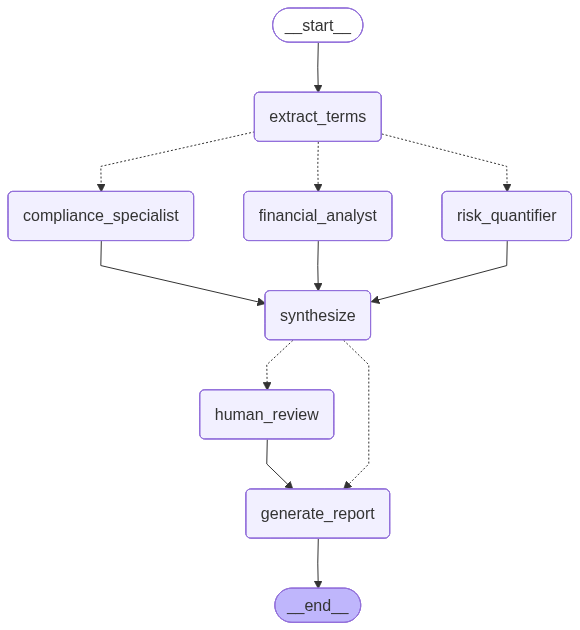

In [11]:
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_ascii())

## Step 10 — Run Pipeline

The `thread_id` is the deal ID — every state transition is checkpointed under that key.

> **If the deal triggers escalation**, the graph pauses at `human_review` and raises `GraphInterrupt`.  
> Resume with `graph.invoke(Command(resume={"decision": "APPROVE", "notes": "..."}), config=config)`

In [13]:
from langgraph.errors import GraphInterrupt

# ── Step 1: Read the PDF ──────────────────────────────────────────────
# PdfReader opens the PDF file and reads each page.
# We join all pages into one long string of text.
reader    = PdfReader("test_deal.pdf")
deal_text = "\n".join(page.extract_text() or "" for page in reader.pages)

# Generate a unique ID for this deal run so we can track it in checkpoints
# uuid4() creates a random ID; we take 6 hex characters and uppercase them, e.g. "DEAL-4A3F91"
deal_id = f"DEAL-{uuid.uuid4().hex[:6].upper()}"

print(f"PDF loaded  : {len(deal_text)} chars")
print(f"Deal ID     : {deal_id}")
print("=" * 60)

# ── Step 2: Set up the starting state ────────────────────────────────
# This is the initial baton — we hand the pipeline the PDF text and a deal ID.
# All other fields start as None or empty — nodes will fill them in as they run.
initial: DealState = {
    "deal_id":             deal_id,
    "deal_text":           deal_text,
    "terms":               None,    # filled in by node_extract
    "specialist_results":  [],      # filled in by the three parallel specialists
    "panel_decision":      None,    # filled in by node_synthesize
    "requires_escalation": False,   # set by node_synthesize
    "human_decision":      None,    # set by node_human_review (if escalated)
    "human_notes":         None,    # set by node_human_review (if escalated)
    "final_report":        None,    # filled in by node_generate_report
}

# thread_id links this run to its checkpoints.
# Use the deal_id so every deal has its own isolated checkpoint history.
config = {"configurable": {"thread_id": deal_id}}

print("\n🚀 Starting Parallel Expert Panel...\n")

try:
    # graph.invoke() runs the entire pipeline from START to END.
    # It returns the final state after all nodes have completed.
    final = graph.invoke(initial, config=config)
    print("\n" + "=" * 60)
    print("✅  Pipeline complete")

except GraphInterrupt:
    # GraphInterrupt is raised when interrupt() is called inside node_human_review.
    # This means the deal was escalated and is waiting for a human decision.
    # The pipeline state is saved — nothing is lost.
    print("\n" + "=" * 60)
    print("⏸️   Pipeline paused — human review required")
    print("\nEdit HUMAN_DECISION below and run the resume cell.")

PDF loaded  : 360 chars
Deal ID     : DEAL-6E1945

🚀 Starting Parallel Expert Panel...


📄 [Extractor] Parsing deal document...
   ✓ Borrower : Acme Corp
   ✓ Amount   : $15,000,000
   ✓ LTV      : 65.0%  DTI: 35.0%  Credit: 720

⚖️  [Compliance Specialist] Running...

📊 [Financial Analyst] Running...

🎲 [Risk Quantifier] Running...


/var/folders/pn/h1mzl1dd37s5hgl79d_c9f340000gn/T/ipykernel_50733/1937154879.py:18: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agent  = create_react_agent(llm, COMPLIANCE_TOOLS, response_format=ComplianceFindings)
/var/folders/pn/h1mzl1dd37s5hgl79d_c9f340000gn/T/ipykernel_50733/1937154879.py:79: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agent  = create_react_agent(llm, RISK_TOOLS, response_format=RiskFindings)


   ✓ Financial health : ADEQUATE
   ✓ Confidence       : 90%
   ✓ Composite score : 15/100 (LOW)
   ✓ Confidence      : 95%
   ✓ Status     : PASS
   ✓ Failed     : none
   ✓ Confidence : 98%

🔮 [Synthesizer] Aggregating specialist panel...
   ✓ AI decision : ESCALATE
   ✓ Risk score  : 15/100
   ✓ Confidence  : 94%
   ✓ Escalation  : True

👤 [Human Review] Escalation triggered — pausing for human input...
{
  "deal_id": "DEAL-6E1945",
  "borrower": "Acme Corp",
  "amount_usd": 15000000.0,
  "ai_decision": "ESCALATE",
  "risk_score": 15.3,
  "confidence": 0.94,
  "summary": "The loan application is fundamentally sound, with all panels reporting positive assessments (Financial: ADEQUATE, Risk: LOW, Compliance: PASS). The average confidence across all panels is high (94%). However, the deal amount ($15,000,000) exceeds the internal threshold for standard approval, triggering an automatic escalation requirement regardless of the favorable metrics. While the risk profile is low and the com

### (Optional) Resume after human review

Only run this cell if the pipeline paused above.

In [14]:
# ── Only run this cell if the pipeline paused above ──────────────────
# Edit HUMAN_DECISION to your chosen outcome before running.

HUMAN_DECISION = "CONDITIONAL_APPROVE"   # options: APPROVE | REJECT | CONDITIONAL_APPROVE
HUMAN_NOTES    = "Escalation reviewed by credit committee. Approved subject to conditions."

# Command(resume=...) tells LangGraph to unpause the pipeline and continue from where it stopped.
# We pass the same config so LangGraph knows which thread (deal) to resume.
# The resume value is handed to interrupt() inside node_human_review as the return value.
final = graph.invoke(
    Command(resume={"decision": HUMAN_DECISION, "notes": HUMAN_NOTES}),
    config=config,
)
print("\n✅  Pipeline resumed and complete")


👤 [Human Review] Escalation triggered — pausing for human input...
{
  "deal_id": "DEAL-6E1945",
  "borrower": "Acme Corp",
  "amount_usd": 15000000.0,
  "ai_decision": "ESCALATE",
  "risk_score": 15.3,
  "confidence": 0.94,
  "summary": "The loan application is fundamentally sound, with all panels reporting positive assessments (Financial: ADEQUATE, Risk: LOW, Compliance: PASS). The average confidence across all panels is high (94%). However, the deal amount ($15,000,000) exceeds the internal threshold for standard approval, triggering an automatic escalation requirement regardless of the favorable metrics. While the risk profile is low and the compliance is clear, the size of the transaction necessitates senior committee review for final authorization.",
  "key_risks": [
    "Deal amount ($15M) exceeds standard approval limits, requiring mandatory escalation."
  ],
  "conditions": [],
  "prompt": "Enter: APPROVE | REJECT | CONDITIONAL_APPROVE  (optionally add '| notes')"
}
   ✓ Huma

## Step 11 — Results

In [15]:
rpt  = final["final_report"]
ds   = rpt["deal_summary"]        
sp   = rpt["specialist_panel"]    
ai   = rpt["ai_recommendation"]  
out  = rpt["final_outcome"]      


comp = sp.get("compliance") or {}
fin  = sp.get("financial")  or {}
risk = sp.get("risk")       or {}

print(f"""
╔══════════════════════════════════════════════════════════════╗
║               DEAL REVIEW REPORT  —  V2                     ║
╚══════════════════════════════════════════════════════════════╝

Deal ID    : {rpt['deal_id']}
Timestamp  : {rpt['timestamp']}

── DEAL SUMMARY ───────────────────────────────────────────────
Borrower   : {ds['borrower']}
Amount     : ${ds['amount_usd']:>15,.0f}
LTV        : {ds['ltv']:.1%}          (max {RULES['max_ltv']:.0%})
DTI        : {ds['dti']:.1%}          (max {RULES['max_dti']:.0%})
Credit     : {ds['credit_score']}           (min {RULES['min_credit_score']})
Rate       : {ds['rate_pct']}%          (max {RULES['max_rate_pct']}%)
Term       : {ds['term_months']} months
Jurisdiction: {ds['jurisdiction']}

── SPECIALIST PANEL ───────────────────────────────────────────
⚖️  Compliance   : {comp.get('status', 'N/A'):20s}  conf {comp.get('confidence', 0):.0%}
📊 Financial    : {fin.get('financial_health', 'N/A'):20s}  conf {fin.get('confidence', 0):.0%}
🎲 Risk Score   : {risk.get('composite_risk_score', 0):.0f}/100 ({risk.get('risk_level', 'N/A'):8s})  conf {risk.get('confidence', 0):.0%}

── AI RECOMMENDATION ──────────────────────────────────────────
Decision   : {ai['decision']}
Risk Score : {ai['overall_risk']:.0f}/100
Confidence : {ai['confidence']:.0%}

── FINAL OUTCOME ──────────────────────────────────────────────
✅ Decision      : {out['decision']}
👤 Escalated     : {out['escalated']}
🔁 Human Override: {out['human_override']}
""")

# Only print these sections if they have content
if out.get("human_notes"):
    print(f"Human notes  : {out['human_notes']}\n")

if ai.get("conditions"):
    print("Conditions:")
    for c in ai["conditions"]:
        print(f"  • {c}")

if ai.get("key_risks"):
    print("\nKey Risks:")
    for r in ai["key_risks"]:
        print(f"  ⚠  {r}")

print(f"\nExecutive Summary:\n{ai['executive_summary']}")


╔══════════════════════════════════════════════════════════════╗
║               DEAL REVIEW REPORT  —  V2                     ║
╚══════════════════════════════════════════════════════════════╝

Deal ID    : DEAL-6E1945
Timestamp  : 2026-05-08T18:35:53.563927

── DEAL SUMMARY ───────────────────────────────────────────────
Borrower   : Acme Corp
Amount     : $     15,000,000
LTV        : 65.0%          (max 80%)
DTI        : 35.0%          (max 43%)
Credit     : 720           (min 620)
Rate       : 5.5%          (max 18.0%)
Term       : 60 months
Jurisdiction: USA

── SPECIALIST PANEL ───────────────────────────────────────────
⚖️  Compliance   : PASS                  conf 98%
📊 Financial    : ADEQUATE              conf 90%
🎲 Risk Score   : 15/100 (LOW     )  conf 95%

── AI RECOMMENDATION ──────────────────────────────────────────
Decision   : ESCALATE
Risk Score : 15/100
Confidence : 94%

── FINAL OUTCOME ──────────────────────────────────────────────
✅ Decision      : CONDITIONAL_A

## Step 12 — Inspect Checkpointed State

Every state transition is stored in `MemorySaver`. You can replay or audit any checkpoint.

In [16]:
history = list(graph.get_state_history(config))

print(f"Checkpoints saved: {len(history)}\n")
for i, snapshot in enumerate(reversed(history)):
    node = snapshot.metadata.get("source", "?") if snapshot.metadata else "?"
    keys = [k for k, v in snapshot.values.items() if v is not None]
    print(f"  [{i:02d}] next={snapshot.next}  populated_keys={keys}")

Checkpoints saved: 7

  [00] next=('__start__',)  populated_keys=['specialist_results']
  [01] next=('extract_terms',)  populated_keys=['deal_id', 'deal_text', 'specialist_results', 'requires_escalation']
  [02] next=('compliance_specialist', 'financial_analyst', 'risk_quantifier')  populated_keys=['deal_id', 'deal_text', 'terms', 'specialist_results', 'requires_escalation']
  [03] next=('synthesize',)  populated_keys=['deal_id', 'deal_text', 'terms', 'specialist_results', 'requires_escalation']
  [04] next=('human_review',)  populated_keys=['deal_id', 'deal_text', 'terms', 'specialist_results', 'panel_decision', 'requires_escalation']
  [05] next=('generate_report',)  populated_keys=['deal_id', 'deal_text', 'terms', 'specialist_results', 'panel_decision', 'requires_escalation', 'human_decision', 'human_notes']
  [06] next=()  populated_keys=['deal_id', 'deal_text', 'terms', 'specialist_results', 'panel_decision', 'requires_escalation', 'human_decision', 'human_notes', 'final_report']
